# Explainable Machine-Learning and Predictive Statistics for Sustainable Photovoltaic Power Prediction on Areal Meteorological Variables
Sajjad Nematzadeh, 
Vedat Esen

## Feature Analysis

### Preparation

#### imports

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import f_regression, SelectKBest
from sklearn import tree
from scipy.stats import ttest_ind
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram, fcluster
from matplotlib.colors import ListedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

#### Data


##### Loading

In [ ]:
dfo = pd.read_csv(fr'data/apw.csv', index_col=None)
# 'Irrediance', 'ModuleTemperature',
# X_cols = ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'apparent_temperature',
#           'precipitation', 'wind_speed_10m', 'wind_speed_80m', 'wind_direction_10m', 'wind_direction_80m', 'wind_gusts_10m',
#           'visibility', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'direct_normal_irradiance', 'global_tilted_irradiance',
#           'terrestrial_radiation', 'is_day']

X_cols = ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'apparent_temperature',
          'precipitation', 'wind_speed_10m', 'wind_speed_80m', 'wind_direction_10m', 'wind_direction_80m', 'wind_gusts_10m',
          'visibility', 'shortwave_radiation_instant', 'direct_radiation_instant', 'diffuse_radiation_instant',
          'direct_normal_irradiance',
          'direct_normal_irradiance_instant', 'global_tilted_irradiance_instant', 'terrestrial_radiation_instant']

X_cols_short = ['tmpr2', 'rlhm2', 'dwpt2', 'aptmp',
                'prcpt', 'wnsp1', 'wnsp8', 'wndr1', 'wndr8', 'wngs1',
                'vsblt', 'shwri', 'drcri', 'dfsri',
                'drnir',
                'drnii', 'gltii', 'trsri']

X_cols_long_to_short = {c: s for c, s in zip(X_cols, X_cols_short)}
X_cols_short_to_long = {s: c for c, s in zip(X_cols, X_cols_short)}

# dfo=dfo[dfo['is_day']==1].reset_index(drop=True)

X = dfo.loc[:, X_cols]
y = dfo['AP']

In [ ]:
X = pd.DataFrame.round(X, 1)
y = pd.DataFrame.round(y, 1)

In [44]:
X_cols_long_to_short

{'temperature_2m': 'tmpr2',
 'relative_humidity_2m': 'rlhm2',
 'dew_point_2m': 'dwpt2',
 'apparent_temperature': 'aptmp',
 'precipitation': 'prcpt',
 'wind_speed_10m': 'wnsp1',
 'wind_speed_80m': 'wnsp8',
 'wind_direction_10m': 'wndr1',
 'wind_direction_80m': 'wndr8',
 'wind_gusts_10m': 'wngs1',
 'visibility': 'vsblt',
 'shortwave_radiation_instant': 'shwri',
 'direct_radiation_instant': 'drcri',
 'diffuse_radiation_instant': 'dfsri',
 'direct_normal_irradiance': 'drnir',
 'direct_normal_irradiance_instant': 'drnii',
 'global_tilted_irradiance_instant': 'gltii',
 'terrestrial_radiation_instant': 'trsri'}

In [ ]:
vdfo = dfo[9000:13000]
plt.figure(figsize=(50, 15))
sns.lineplot(vdfo, x=vdfo.index, y='Irrediance')
# sns.lineplot(vdfo, x=vdfo.index, y='direct_normal_irradiance_instant', alpha=0.7)
# sns.lineplot(vdfo, x=vdfo.index, y='AP', alpha=0.5)
sns.lineplot(vdfo, x=vdfo.index, y='direct_normal_irradiance', alpha=0.7)
plt.show()
sns.histplot(x=dfo['Irrediance'], y=dfo['direct_normal_irradiance_instant'], bins=5)
plt.show()

##### Wind to one-hot

In [4]:
categories = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
bins = [0, 45, 90, 135, 180, 225, 270, 315, 360]
bins = np.append(bins, 360)
categories.append('N')
indices = np.digitize(X['wind_direction_10m'] % 360, bins, right=False) - 1
wind_direction_cat = [categories[i] for i in indices]

wind_orders = ['wind_N', 'wind_NE', 'wind_E', 'wind_SE', 'wind_S', 'wind_SW', 'wind_W', 'wind_NW']
tdf = pd.get_dummies(wind_direction_cat, prefix='wind').astype(int)

X = pd.concat([X, tdf[wind_orders]], axis=1)

##### Scaling

In [71]:
scaler = MinMaxScaler()
scaler.fit(X)
Xnorm = pd.DataFrame(scaler.transform(X), columns=X.columns)
Xnorm.head()

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,wind_speed_10m,wind_speed_80m,wind_direction_10m,wind_direction_80m,wind_gusts_10m,visibility,shortwave_radiation_instant,direct_radiation_instant,diffuse_radiation_instant,direct_normal_irradiance,direct_normal_irradiance_instant,global_tilted_irradiance_instant,terrestrial_radiation_instant
0,0.676259,0.518519,0.824451,0.690945,0.0,0.283673,0.335570,0.181667,0.181389,0.325424,0.296698,0.0,0.006932,0.0,0.0,0.0,0.0,0.0
1,0.671463,0.530864,0.827586,0.690945,0.0,0.275510,0.332886,0.170556,0.173056,0.328814,0.296698,0.0,0.006932,0.0,0.0,0.0,0.0,0.0
2,0.666667,0.530864,0.824451,0.687008,0.0,0.267347,0.323490,0.146667,0.153889,0.312994,0.296698,0.0,0.006932,0.0,0.0,0.0,0.0,0.0
3,0.661871,0.543210,0.824451,0.685039,0.0,0.259184,0.311409,0.125000,0.133611,0.292655,0.296698,0.0,0.006932,0.0,0.0,0.0,0.0,0.0
4,0.657074,0.555556,0.827586,0.683071,0.0,0.255102,0.304698,0.108889,0.119722,0.272316,0.296698,0.0,0.006932,0.0,0.0,0.0,0.0,0.0


In [77]:
Xn = X

## Results

### Statistical Selection

#### Variance

A variance threshold of 0.01 is commonly used as a heuristic for identifying low-variance features in normalized datasets [1,2].

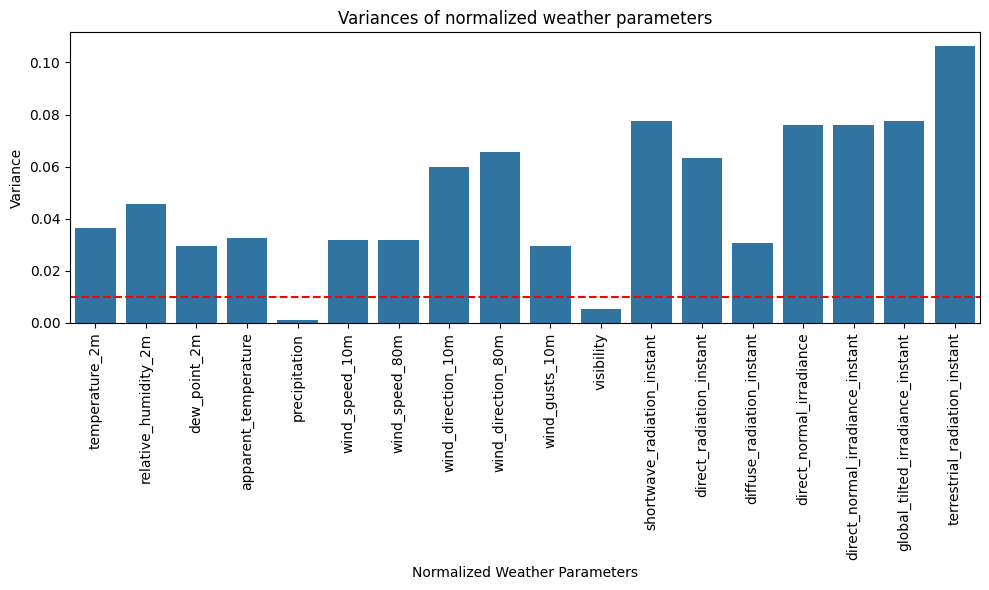

In [72]:
plt.figure(figsize=(10, 6))
var_Xn = Xnorm.var()
sns.barplot(data=var_Xn)
plt.xticks(rotation=90)
plt.title('Variances of normalized weather parameters')
plt.xlabel('Normalized Weather Parameters')
plt.ylabel('Variance')
plt.tight_layout()
var_threshold = 0.01
plt.axhline(y=var_threshold, color='r', linestyle='--', label=f'Threshold ({var_threshold})')

In [73]:
Xnormr = Xnorm.drop(columns=Xnorm.loc[:, Xnorm.var() < var_threshold].columns)
Xnormr.head()

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,wind_speed_10m,wind_speed_80m,wind_direction_10m,wind_direction_80m,wind_gusts_10m,shortwave_radiation_instant,direct_radiation_instant,diffuse_radiation_instant,direct_normal_irradiance,direct_normal_irradiance_instant,global_tilted_irradiance_instant,terrestrial_radiation_instant
0,0.676259,0.518519,0.824451,0.690945,0.283673,0.335570,0.181667,0.181389,0.325424,0.0,0.006932,0.0,0.0,0.0,0.0,0.0
1,0.671463,0.530864,0.827586,0.690945,0.275510,0.332886,0.170556,0.173056,0.328814,0.0,0.006932,0.0,0.0,0.0,0.0,0.0
2,0.666667,0.530864,0.824451,0.687008,0.267347,0.323490,0.146667,0.153889,0.312994,0.0,0.006932,0.0,0.0,0.0,0.0,0.0
3,0.661871,0.543210,0.824451,0.685039,0.259184,0.311409,0.125000,0.133611,0.292655,0.0,0.006932,0.0,0.0,0.0,0.0,0.0
4,0.657074,0.555556,0.827586,0.683071,0.255102,0.304698,0.108889,0.119722,0.272316,0.0,0.006932,0.0,0.0,0.0,0.0,0.0


#### Hierarchical Clustering

In [76]:
correlation_matrix = Xn.corr(method='pearson')
linkage_matrix = sch.linkage(correlation_matrix, method='ward')
dendro_order = sch.leaves_list(linkage_matrix)
reordered_correlation_matrix = correlation_matrix.iloc[dendro_order, dendro_order]
reordered_correlation_matrix.columns

Index(['relative_humidity_2m', 'wind_direction_10m', 'wind_direction_80m',
       'precipitation', 'visibility', 'diffuse_radiation_instant',
       'direct_radiation_instant', 'direct_normal_irradiance',
       'direct_normal_irradiance_instant', 'terrestrial_radiation_instant',
       'shortwave_radiation_instant', 'global_tilted_irradiance_instant',
       'wind_speed_80m', 'wind_speed_10m', 'wind_gusts_10m', 'dew_point_2m',
       'temperature_2m', 'apparent_temperature'],
      dtype='object')

In [77]:
def select_features_hc(linkage_matrix, threshold, correlation_matrix):
    clusters = fcluster(linkage_matrix, t=threshold, criterion='distance')
    cluster_mapping = pd.DataFrame({'Feature': correlation_matrix.columns, 'Cluster': clusters})
    selected_features = []
    for cluster_id in cluster_mapping['Cluster'].unique():
        cluster_features = cluster_mapping[cluster_mapping['Cluster'] == cluster_id]['Feature']
        cluster_corr = correlation_matrix.loc[cluster_features, cluster_features]
        feature_with_max_corr = cluster_corr.sum(axis=1).idxmax()
        selected_features.append(feature_with_max_corr)
    return selected_features

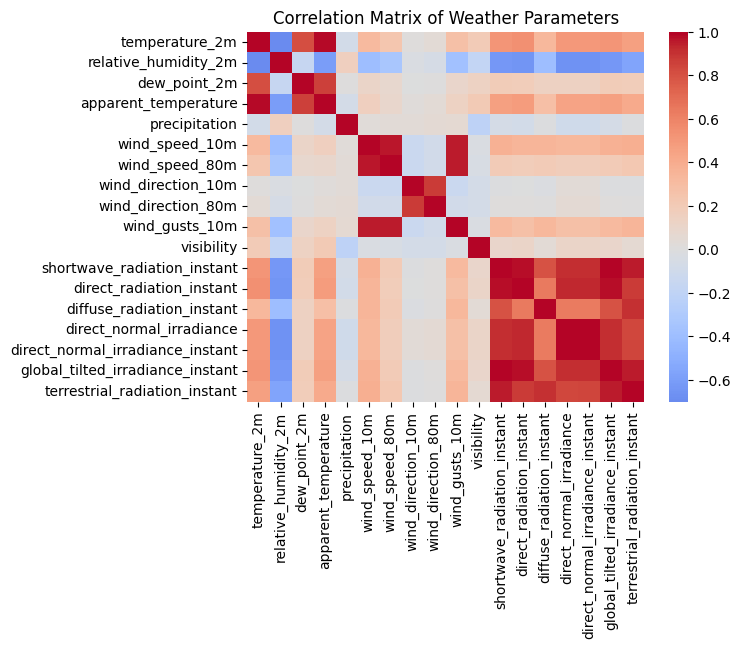

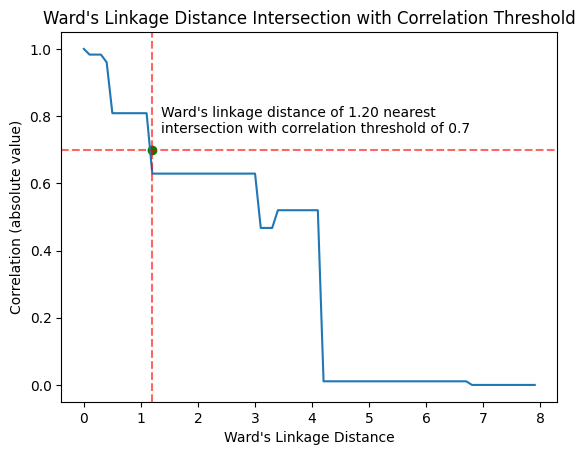

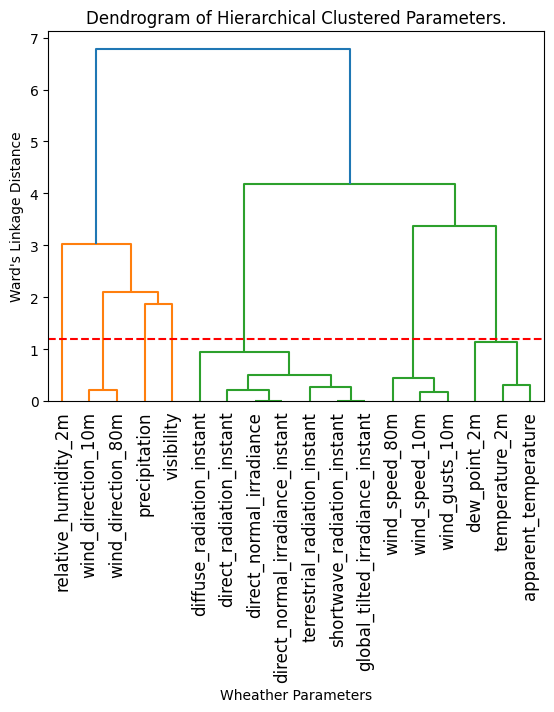

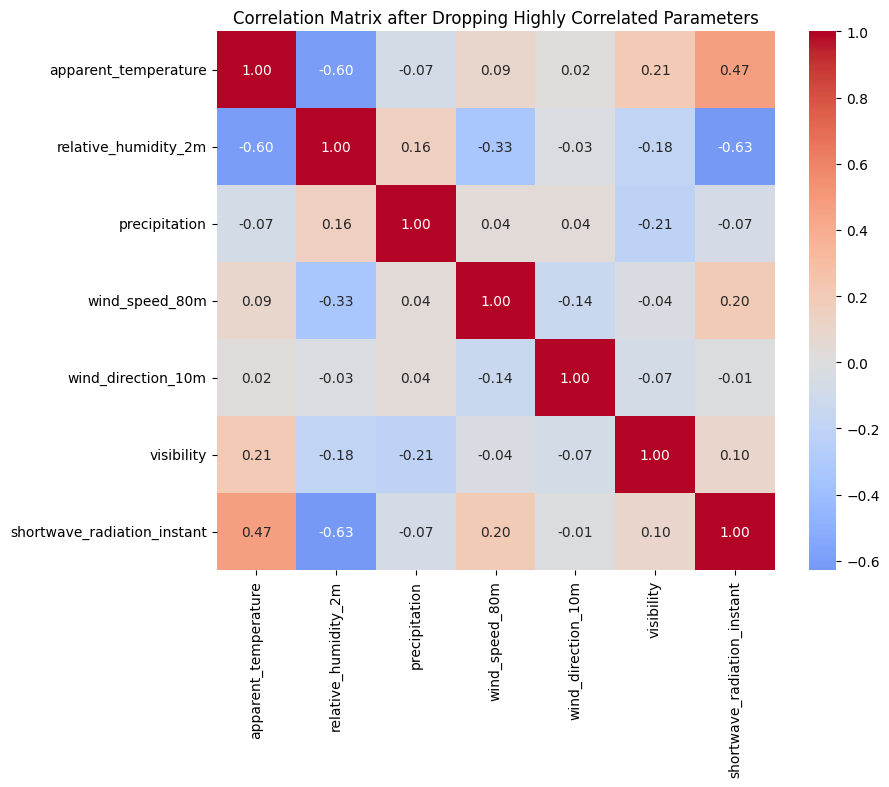

In [78]:
corr_max = []
distances = np.arange(0, 8, 0.1)
for dst in distances:
    selected_features = select_features_hc(linkage_matrix, dst, correlation_matrix)
    reduced_df = Xn[selected_features]
    reduced_corr = reduced_df.corr()
    corr_max += [np.abs(np.triu(reduced_corr, k=1)).max()]

corr_max = np.array(corr_max)
corr_threshold = 0.7
id_dist = np.argmax(corr_max < corr_threshold)
dst = distances[id_dist]
# dst = (distances[id_dist-1]+distances[id_dist])/2


selected_features = select_features_hc(linkage_matrix, dst, correlation_matrix)
reduced_df = Xn[selected_features]

reduced_corr = reduced_df.corr()


plt.figure()
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=False, center=0)
plt.title('Correlation Matrix of Weather Parameters')
plt.show()


plt.figure()
sns.lineplot(x=distances, y=corr_max)
plt.title("Ward's Linkage Distance Intersection with Correlation Threshold")
plt.xlabel("Ward's Linkage Distance")
plt.ylabel("Correlation (absolute value)")
plt.axhline(y=corr_threshold, color='r', linestyle='--', alpha=0.6)
plt.axvline(x=dst, color='r', linestyle='--', alpha=0.6)
plt.text(dst+0.15, corr_threshold+0.05, f"Ward's linkage distance of {dst:.2f} nearest \nintersection with correlation threshold of {corr_threshold}")
plt.scatter(dst, corr_threshold, marker='o', color='green')
plt.show()

plt.figure()
dendrogram(linkage_matrix, leaf_rotation=90, labels=correlation_matrix.columns)
plt.axhline(y=dst, color='r', linestyle='--')  # Visualize the threshold
plt.title(f'Dendrogram of Hierarchical Clustered Parameters.')
# plt.title(f'Dendrogram of Hierarchical Clustered Parameters. Max |correlation|: {np.abs(np.triu(reduced_corr,k=1)).max():.2f} ')
plt.xlabel("Wheather Parameters")
plt.ylabel("Ward's Linkage Distance")
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(reduced_corr, cmap='coolwarm', annot=True, center=0, fmt='.2f')
plt.title('Correlation Matrix after Dropping Highly Correlated Parameters')
plt.show()

In [78]:
Xn

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,wind_speed_10m,wind_speed_80m,wind_direction_10m,wind_direction_80m,wind_gusts_10m,visibility,shortwave_radiation_instant,direct_radiation_instant,diffuse_radiation_instant,direct_normal_irradiance,direct_normal_irradiance_instant,global_tilted_irradiance_instant,terrestrial_radiation_instant
0,25.4,61.0,17.3,25.9,0.0,13.9,25.0,65.4,65.3,29.2,24140.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,25.2,62.0,17.4,25.9,0.0,13.5,24.8,61.4,62.3,29.5,24140.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,25.0,62.0,17.3,25.7,0.0,13.1,24.1,52.8,55.4,28.1,24140.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,24.8,63.0,17.3,25.6,0.0,12.7,23.2,45.0,48.1,26.3,24140.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,24.6,64.0,17.4,25.5,0.0,12.5,22.7,39.2,43.1,24.5,24140.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70381,33.2,33.0,14.8,33.7,0.0,7.4,9.9,309.1,313.5,18.0,78540.0,186.7,118.1,68.6,461.0,461.0,186.7,340.2
70382,32.7,34.0,14.8,33.3,0.0,6.5,8.9,303.7,310.1,16.6,78160.0,142.7,82.5,60.1,396.2,396.2,142.7,276.8
70383,32.1,36.0,15.2,33.0,0.0,5.8,8.0,299.7,305.8,14.8,77800.0,101.0,53.1,47.9,330.8,330.8,101.0,213.2
70384,31.5,37.0,15.1,32.5,0.0,4.7,6.8,292.6,302.0,13.3,77420.0,62.8,29.7,33.0,263.5,263.5,62.8,149.9


In [79]:
Xnc = Xn.drop(columns=Xnorm.loc[:, Xnorm.var() < var_threshold].columns)
Xnc

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,wind_speed_10m,wind_speed_80m,wind_direction_10m,wind_direction_80m,wind_gusts_10m,shortwave_radiation_instant,direct_radiation_instant,diffuse_radiation_instant,direct_normal_irradiance,direct_normal_irradiance_instant,global_tilted_irradiance_instant,terrestrial_radiation_instant
0,25.4,61.0,17.3,25.9,13.9,25.0,65.4,65.3,29.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,25.2,62.0,17.4,25.9,13.5,24.8,61.4,62.3,29.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,25.0,62.0,17.3,25.7,13.1,24.1,52.8,55.4,28.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,24.8,63.0,17.3,25.6,12.7,23.2,45.0,48.1,26.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,24.6,64.0,17.4,25.5,12.5,22.7,39.2,43.1,24.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70381,33.2,33.0,14.8,33.7,7.4,9.9,309.1,313.5,18.0,186.7,118.1,68.6,461.0,461.0,186.7,340.2
70382,32.7,34.0,14.8,33.3,6.5,8.9,303.7,310.1,16.6,142.7,82.5,60.1,396.2,396.2,142.7,276.8
70383,32.1,36.0,15.2,33.0,5.8,8.0,299.7,305.8,14.8,101.0,53.1,47.9,330.8,330.8,101.0,213.2
70384,31.5,37.0,15.1,32.5,4.7,6.8,292.6,302.0,13.3,62.8,29.7,33.0,263.5,263.5,62.8,149.9


### Machine Learning Driven

In [80]:
X_train, X_test, y_train, y_test = train_test_split(Xnc, y, test_size=0.1, random_state=42)
X_train.head()
# X_train = X_train.values
# X_test = X_test.values
# y_train = y_train.values
# y_test = y_test.values

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,wind_speed_10m,wind_speed_80m,wind_direction_10m,wind_direction_80m,wind_gusts_10m,shortwave_radiation_instant,direct_radiation_instant,diffuse_radiation_instant,direct_normal_irradiance,direct_normal_irradiance_instant,global_tilted_irradiance_instant,terrestrial_radiation_instant
23189,13.0,33.0,-2.9,9.8,4.6,6.2,321.3,324.5,11.9,261.7,193.9,67.7,646.6,646.6,261.7,411.6
4,24.6,64.0,17.4,25.5,12.5,22.7,39.2,43.1,24.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0
61571,16.0,78.0,12.1,15.6,6.8,14.0,212.0,221.9,16.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0
40010,18.9,49.0,8.0,17.5,6.1,4.7,139.8,270.0,8.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0
48840,6.8,88.0,5.0,4.3,8.6,14.6,165.4,200.2,12.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Tree-based

In [14]:
# model = tree.DecisionTreeRegressor()
num_feat_ub = 6
depth_ub = 20
mses = np.zeros((num_feat_ub, depth_ub))
r2s = np.zeros((num_feat_ub, depth_ub))


print(f'Grid searh for {depth_ub} depths and {num_feat_ub} max features')
print('mf,dp', end=':\t')
for depth in range(depth_ub):
    print(depth, end='\t')
print()
for num_feat in range(num_feat_ub):
    print(f'\n{num_feat}', end=':\t')
    for depth in range(depth_ub):
        mdl = RandomForestRegressor(max_depth=depth+1, max_features=num_feat+1)
        # mdl = RandomForestRegressor(max_features=i)
        mdl = mdl.fit(X_train, y_train)
        y_pred = mdl.predict(X_test)
        mse = mean_squared_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        mses[num_feat, depth] = mse
        r2s[num_feat, depth] = r2
        print(f'{r2*100:.1f}', end='\t')
        # print(f"Depth: {depth+1} , max features: {num_feat+1}) Mean Squared Error: {mse:.2f} , RMSE:{mse**0.5:.2f}")

Grid searh for 20 depths and 6 max features
mf,dp:	0	1	2	3	4	5	6	7	8	9	10	11	12	13	14	15	16	17	18	19	

0:	56.1	73.7	84.3	87.3	88.9	90.0	90.9	91.4	91.9	92.4	92.7	93.0	93.4	93.6	93.7	93.9	94.0	94.0	94.2	94.2	
1:	69.3	84.6	88.9	90.3	91.1	91.5	91.9	92.1	92.4	92.7	93.0	93.2	93.4	93.6	93.7	93.8	93.9	93.9	94.0	94.1	
2:	76.1	87.5	90.2	91.1	91.4	91.7	92.0	92.2	92.4	92.7	93.0	93.1	93.3	93.5	93.6	93.7	93.8	93.8	93.8	93.8	
3:	77.6	88.6	90.6	91.1	91.5	91.8	92.0	92.2	92.5	92.7	92.9	93.1	93.3	93.4	93.5	93.6	93.6	93.7	93.8	93.8	
4:	77.6	88.9	90.6	91.3	91.5	91.7	92.0	92.2	92.5	92.7	92.9	93.0	93.2	93.4	93.5	93.6	93.6	93.7	93.6	93.7	
5:	77.6	88.9	90.9	91.3	91.5	91.8	92.0	92.2	92.5	92.6	92.9	93.0	93.2	93.3	93.4	93.5	93.5	93.6	93.6	93.7	

In [16]:
pd.DataFrame(r2s).to_csv(fr'data/dt_r2s.csv')
pd.DataFrame(mses).to_csv(fr'data/dt_mses.csv')

In [37]:
r2s = pd.read_csv(fr'data/dt_r2s.csv', index_col=0)
mses = pd.read_csv(fr'data/dt_mses.csv', index_col=0)

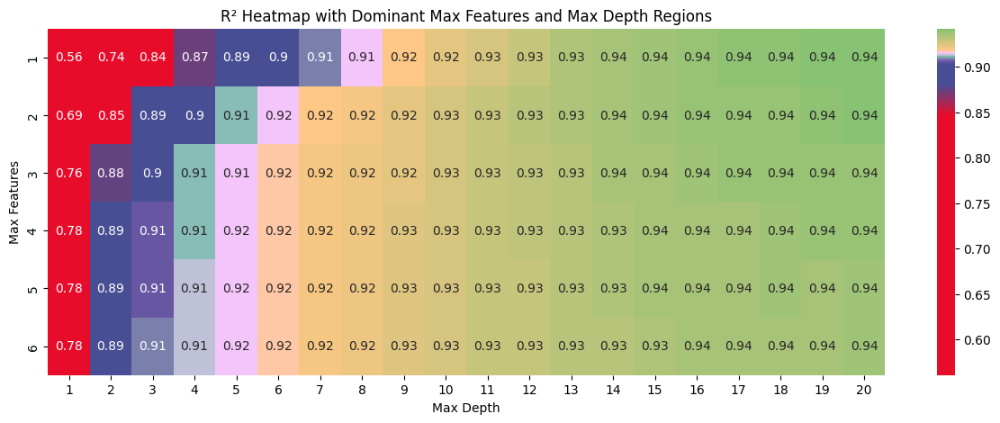

In [96]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors


def generate_bright_colors(n):
    colors = []
    for _ in range(n):
        color = np.random.rand(3)  # Random RGB values
        color /= np.max(color)  # Normalize to ensure brightness
        colors.append(color)
    return colors


plt.figure(figsize=(15, 5))
matrix = (np.round(r2s, 3))
max_features_values = np.arange(1, matrix.shape[0]+1)  # Example values for max_features (index)
max_depth_values = np.arange(1, matrix.shape[1]+1)  # Example values for max_depth (columns)

# Find the dominant max_features and max_depth for different regions of R²
# thresholds = np.linspace(matrix.min(), matrix.max(), 7)  # Define R² regions
thresholds = [0.0, 0.75, 0.84, 0.9, 0.91, 0.92, 0.93, 0.94, 1]  # Define R² regions

dominant_regions = np.zeros_like(matrix).astype(float)
for i, threshold in enumerate(thresholds[:-1]):
    mask = (matrix >= threshold) & (matrix < thresholds[i + 1])
    dominant_regions[mask] = i + 1

# Plot the heatmap
colors = ["#E80C2B", "#E80C2B", "#474E93", "#474E93", "#7E5CAD", "#72BAA9", "#FCC6FF",  "#FFC785", "#88C273", "#72BAA9"]
# colors = generate_bright_colors(len(thresholds))
# colors[1] = colors[2]
bounds = thresholds
cmap = ListedColormap(colors)
cmap = mcolors.LinearSegmentedColormap.from_list('cc', list(zip(thresholds, colors)))


sns.heatmap(matrix, annot=True, cmap=cmap, xticklabels=max_depth_values, yticklabels=max_features_values)

# # Overlay contour lines for dominant regions
# contour = plt.contour(dominant_regions, levels=np.arange(1, len(thresholds)), colors='black', linewidths=.5)
# plt.clabel(contour, inline=True, fontsize=10, fmt="%d")

plt.xlabel("Max Depth")
plt.ylabel("Max Features")
plt.title("R² Heatmap with Dominant Max Features and Max Depth Regions")
plt.show()

Text(0.5, 1.0, 'R² Heatmap with Dominant Max Features and Max Depth Regions')

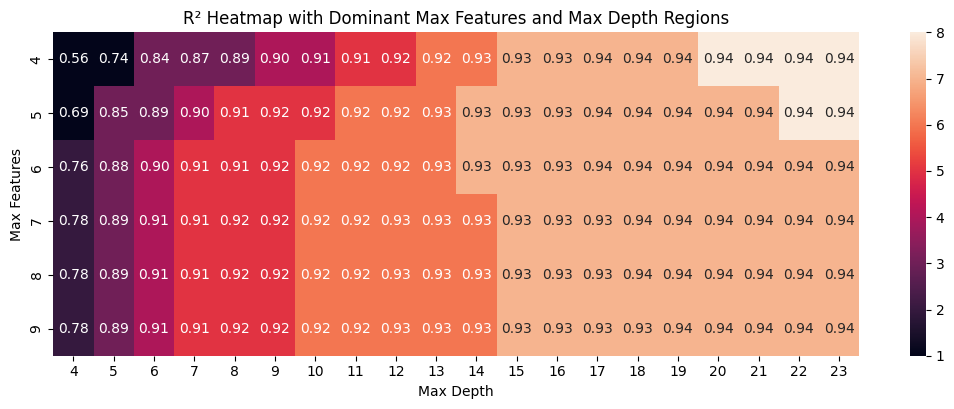

In [100]:
plt.figure(figsize=(13, 4.2))
dominant_regions = pd.DataFrame(dominant_regions)
dominant_regions.index = dominant_regions.index+1
dominant_regions.columns = dominant_regions.columns+1


sns.heatmap(dominant_regions, annot=matrix, fmt='.2f')
plt.xlabel("Max Depth")
plt.ylabel("Max Features")
plt.title("R² Heatmap with Dominant Max Features and Max Depth Regions")

In [87]:
df_dominant_regions = pd.DataFrame(dominant_regions)
dom_rows = []
for i in range(len(thresholds)):
    df_sub = df_dominant_regions[df_dominant_regions == i].dropna(how='all', axis=0).dropna(how='all', axis=1).fillna(0)
    dom_rows += [df_sub.index.max()+1]

    print(f"-----------{i}-------------")
    for c in df_sub.columns:
        # print(min(dom_rows))
        # rows=
        M = df_sub[c].idxmax()
        dom_rows += [M]
        tmp = df_sub[c][(df_sub[c] < M)]
        if tmp.shape[0] > 0:
            print((c, tmp[0]))
    # display(df_sub)

-----------0-------------
-----------1-------------
-----------2-------------
-----------3-------------
(1, 0.0)
-----------4-------------
(2, 0.0)
(3, 0.0)
-----------5-------------
(3, 0.0)
(4, 0.0)
(5, 0.0)
(6, 0.0)
-----------6-------------
(6, 0.0)
(7, 0.0)
(8, 0.0)
-----------7-------------
(10, 0.0)
(16, 0.0)
(17, 0.0)
(18, 0.0)
(19, 0.0)
-----------8-------------


In [ ]:
tree_importances = []
for estimator in mdl.estimators_:
    tree_importances += [estimator.feature_importances_]
df_tree = pd.DataFrame(np.round(np.array(tree_importances), 2), columns=X_train.columns)
df_tree

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,wind_speed_10m,wind_speed_80m,wind_direction_10m,wind_direction_80m,wind_gusts_10m,shortwave_radiation_instant,direct_radiation_instant,diffuse_radiation_instant,direct_normal_irradiance,direct_normal_irradiance_instant,global_tilted_irradiance_instant,terrestrial_radiation_instant
0,0.00,0.00,0.00,0.01,0.00,0.0,0.0,0.0,0.0,0.16,0.01,0.13,0.00,0.68,0.01,0.00
1,0.00,0.00,0.01,0.00,0.00,0.0,0.0,0.0,0.0,0.09,0.09,0.01,0.00,0.75,0.03,0.02
2,0.04,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.07,0.07,0.11,0.69,0.00,0.02,0.00
3,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.01,0.79,0.00,0.00,0.00,0.19,0.00
4,0.00,0.00,0.01,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.10,0.07,0.01,0.00,0.04,0.77
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0.01,0.34,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.35,0.01,0.00,0.02,0.01,0.00,0.25
96,0.02,0.00,0.00,0.00,0.15,0.0,0.0,0.0,0.0,0.29,0.00,0.00,0.00,0.00,0.52,0.02
97,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.08,0.79,0.00,0.00,0.00,0.12,0.01
98,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.12,0.01,0.01,0.00,0.06,0.02,0.78


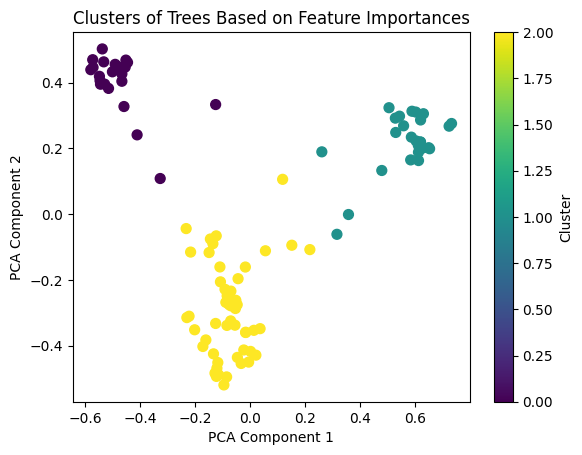

In [ ]:
n_clusters = 3
tree_importances = []
for estimator in mdl.estimators_:
    tree_importances += [estimator.feature_importances_]
df_tree = pd.DataFrame(np.round(np.array(tree_importances), 2), columns=X_train.columns)

kmeanst = KMeans(n_clusters=n_clusters)
clusterst = kmeanst.fit_predict(df_tree)
pcat = PCA(n_components=2)
reduced_datat = pcat.fit_transform(df_tree)

plt.scatter(reduced_datat[:, 0], reduced_datat[:, 1], c=clusterst, cmap="viridis", s=50)
plt.colorbar(label="Cluster")
plt.title("Clusters of Trees Based on Feature Importances")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()
df_tree['cluster'] = clusterst

In [ ]:
df_treet = df_tree.copy()
df_treet['cluster'] = clusterst
df_tree_mean = df_treet.groupby('cluster').median().T.reset_index(names=['Parameter'])
# df_tree_mean.columns = ['Parameter']+[f'Cluster_{c}' for c in list(df_tree_mean.columns)[1:]]
df_tree_mean['overall'] = df_tree_mean.iloc[:, 1:].max(axis=1)
df_tree_mean = df_tree_mean.sort_values(['overall'], ascending=False).drop(columns=['overall'])
df_tree_mean

cluster,Parameter,0,1,2
9,shortwave_radiation_instant,0.030,0.84,0.04
14,global_tilted_irradiance_instant,0.030,0.02,0.83
10,direct_radiation_instant,0.080,0.00,0.01
15,terrestrial_radiation_instant,0.075,0.01,0.01
12,direct_normal_irradiance,0.005,0.00,0.00
0,temperature_2m,0.000,0.00,0.00
2,dew_point_2m,0.000,0.00,0.00
1,relative_humidity_2m,0.000,0.00,0.00
7,wind_direction_80m,0.000,0.00,0.00
6,wind_direction_10m,0.000,0.00,0.00


In [ ]:
vdf_tree = df_tree.melt(id_vars=['cluster'], var_name='Parameter', value_name='Importance')
vdf_tree

,cluster,Parameter,Importance
0,2,temperature_2m,0.00
1,2,temperature_2m,0.00
2,2,temperature_2m,0.04
3,2,temperature_2m,0.00
4,2,temperature_2m,0.00
...,...,...,...
1595,2,terrestrial_radiation_instant,0.25
1596,0,terrestrial_radiation_instant,0.02
1597,2,terrestrial_radiation_instant,0.01
1598,2,terrestrial_radiation_instant,0.78


c:\Users\AptaLap\.conda\envs\daily\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the boxplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


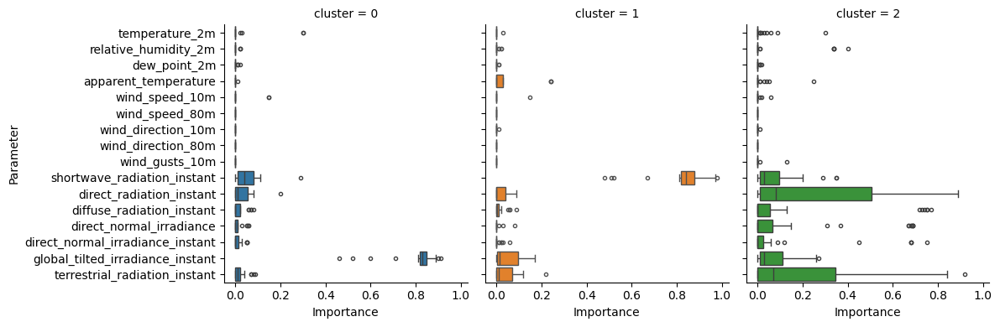

In [ ]:
g = sns.FacetGrid(vdf_tree, col="cluster", hue='cluster', sharex=True, height=4)
g.map(sns.boxplot, "Importance", "Parameter", flierprops={"marker": "."})
# sns.boxplot(data=vdf_tree,y='Parameter',x='Importance',hue='cluster')

In [307]:
df_tree['cluster'] = clusters
# df_tree_agg = pd.DataFrame({
#     'Mean': np.round(df_tree.groupby('cluster', as_index=False).mean(), 2),
#     'Std': np.round(df_tree.groupby('cluster', as_index=False).std(), 2),
#     'Min': df_tree.groupby('cluster', as_index=False).min(),
#     'Max': df_tree.groupby('cluster', as_index=False).max(),
# })
# df_tree_agg = df_tree_agg.sort_values('Mean', ascending=False)

df_tree_mean = df_tree.groupby('cluster', as_index=True).mean().T.reset_index(names=['Parameter'])
# df_tree_mean.columns = ['Parameter']+[f'Cluster_{c}' for c in list(df_tree_mean.columns)[1:]]
df_tree_mean['overall'] = df_tree_mean.iloc[:, 1:].max(axis=1)
df_tree_mean = df_tree_mean.sort_values(['overall'], ascending=False).drop(columns=['overall'])
df_tree_mean

cluster,Parameter,0,1,2,3
14,global_tilted_irradiance_instant,0.236136,0.500769,0.321579,0.286667
9,shortwave_radiation_instant,0.202273,0.116154,0.151053,0.253750
15,terrestrial_radiation_instant,0.147045,0.076923,0.206316,0.069167
10,direct_radiation_instant,0.125682,0.147692,0.150000,0.155833
11,diffuse_radiation_instant,0.091591,0.063846,0.050000,0.125000
13,direct_normal_irradiance_instant,0.104773,0.066923,0.053684,0.050833
12,direct_normal_irradiance,0.052727,0.007692,0.016316,0.004583
1,relative_humidity_2m,0.017045,0.000000,0.030000,0.021250
3,apparent_temperature,0.004091,0.003077,0.000000,0.015000
4,wind_speed_10m,0.010455,0.000000,0.008421,0.001667


In [ ]:
med = df_tree.groupby('cluster', as_index=True).max().T
# med[med>0.005]
med

cluster,0,1,2,3
temperature_2m,0.32,0.00,0.03,0.03
relative_humidity_2m,0.41,0.00,0.02,0.33
dew_point_2m,0.03,0.02,0.00,0.02
apparent_temperature,0.24,0.24,0.03,0.04
wind_speed_10m,0.06,0.00,0.00,0.15
wind_speed_80m,0.00,0.00,0.00,0.00
wind_direction_10m,0.07,0.00,0.00,0.01
wind_direction_80m,0.02,0.00,0.01,0.00
wind_gusts_10m,0.01,0.00,0.00,0.00
shortwave_radiation_instant,0.45,0.11,0.19,0.98


c:\Users\AptaLap\.conda\envs\daily\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


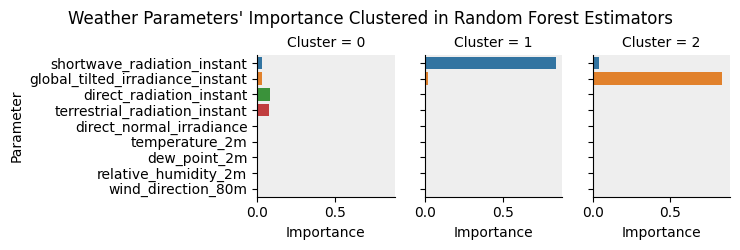

In [355]:
vdf_tree_mean = df_tree_mean[:n_clusters*3].melt(id_vars=['Parameter'], var_name='Cluster', value_name='Importance')

g = sns.FacetGrid(vdf_tree_mean, col="Cluster", hue='Parameter', sharex=True, height=2.5)
g.map(sns.barplot, "Importance", "Parameter")
g.figure.subplots_adjust(top=0.8)
g.figure.suptitle("Weather Parameters' Importance Clustered in Random Forest Estimators")
for ax in g.axes.flatten():
    ax.set_facecolor("#eeeeee")
    ax.grid(True, which='minor', linestyle='--', linewidth=0.5)

In [356]:
clusterst

array([2, 2, 2, 2, 2, 2, 0, 1, 1, 1, 1, 2, 2, 1, 1, 2, 2, 2, 1, 2, 2, 2,
       1, 0, 1, 0, 1, 2, 2, 2, 0, 0, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 0, 1,
       2, 0, 0, 2, 1, 0, 2, 0, 0, 1, 2, 1, 1, 1, 2, 1, 2, 2, 2, 2, 0, 0,
       2, 2, 1, 0, 2, 2, 1, 2, 2, 0, 2, 2, 1, 1, 2, 0, 1, 2, 0, 2, 0, 0,
       0, 2, 1, 1, 0, 0, 2, 2, 0, 2, 2, 2], dtype=int32)

Text(0.5, 1.0, 'Estimator tree of Cluster 1')

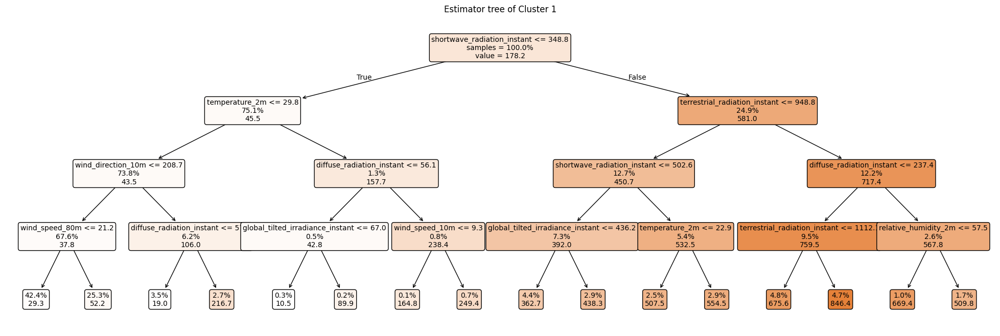

In [ ]:
fig = plt.figure(figsize=(25, 8))
estimator_index = 8
short_cols = [X_cols_long_to_short[c] for c in list(X_train.columns)]
short_cols = X_train.columns
_ = tree.plot_tree(decision_tree=mdl.estimators_[estimator_index],
                   max_depth=7,
                   feature_names=short_cols,
                   label='root',

                   #    class_names=iris.target_names,
                   fontsize=10,
                   proportion=True,
                   rounded=True,
                   impurity=False,
                   precision=1,
                   filled=True)
plt.title(f"Estimator tree of Cluster {clusterst[estimator_index]}")

C:\Users\AptaLap\AppData\Local\Temp\ipykernel_27824\319443899.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=(18, 4))


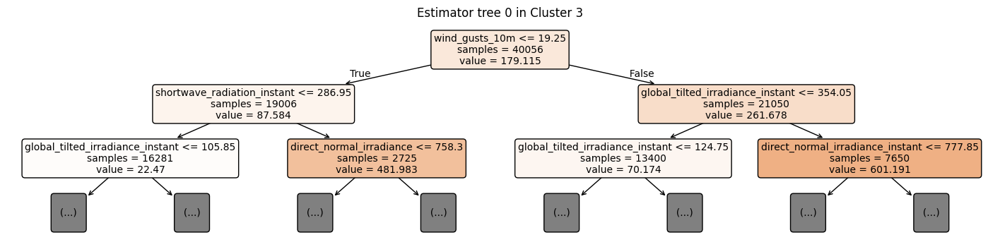

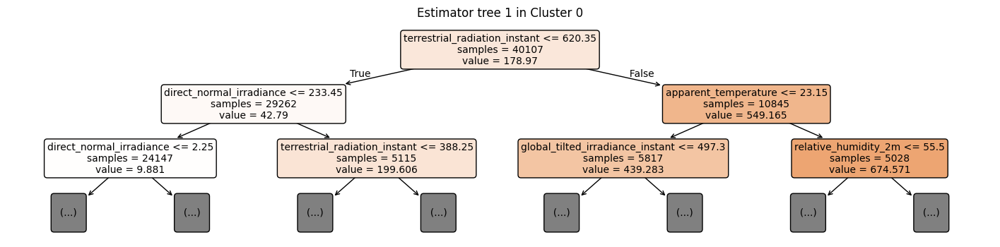

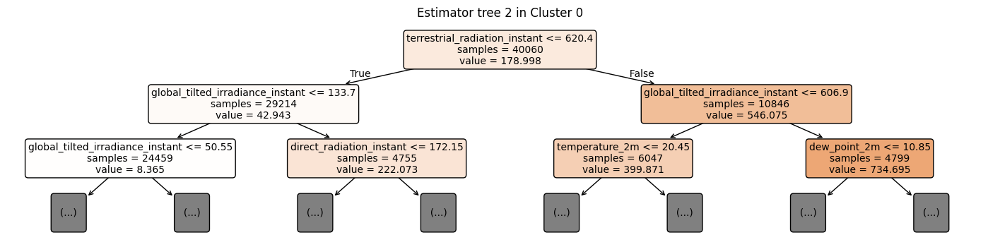

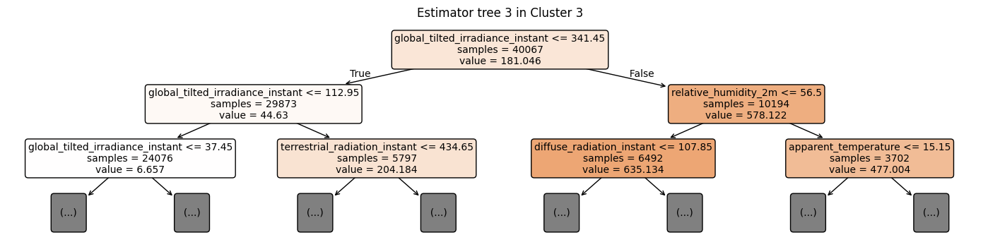

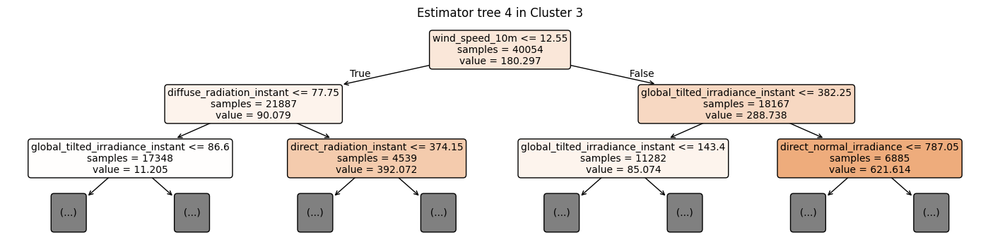

...

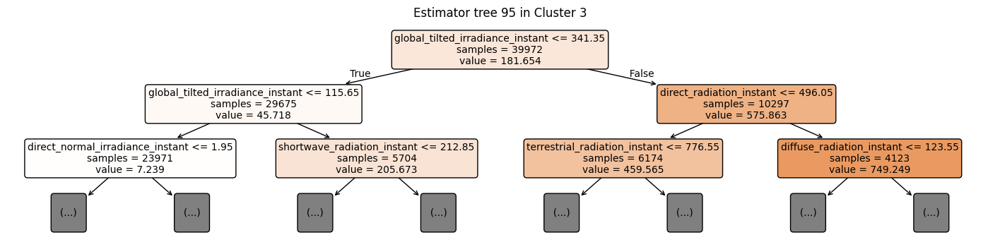

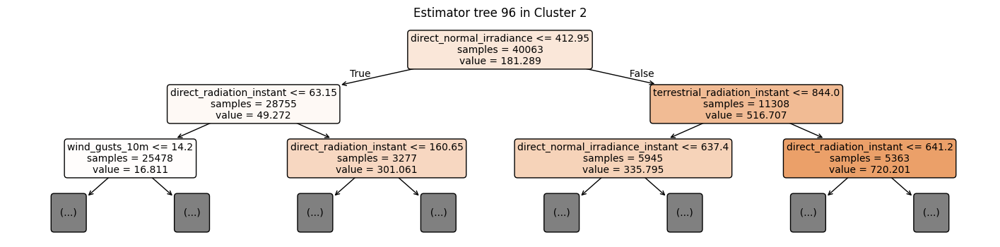

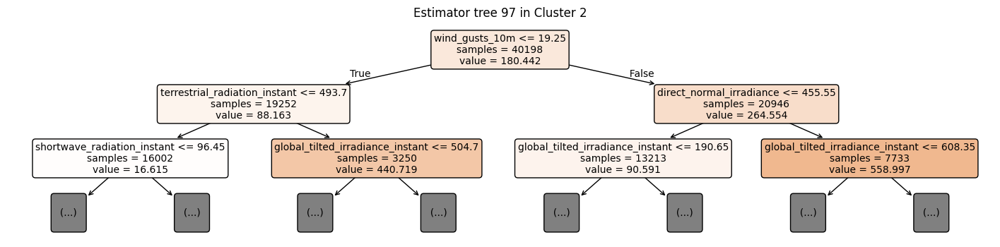

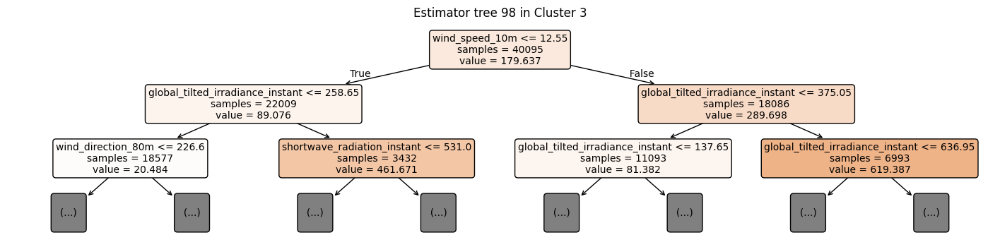

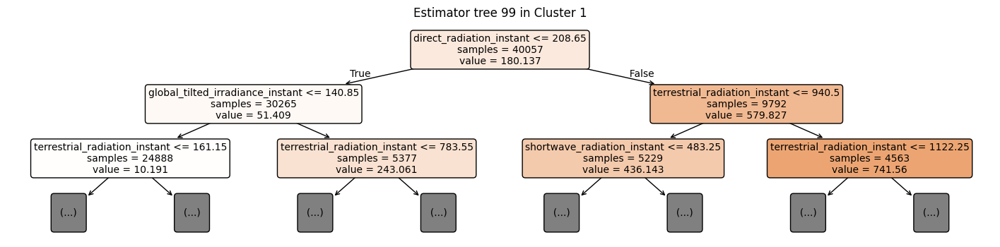

In [ ]:
for ei in range(100):
    fig = plt.figure(figsize=(18, 4))
    estimator_index = ei
    _ = tree.plot_tree(mdl.estimators_[estimator_index],
                       max_depth=2,
                       feature_names=X_train.columns,
                       #    class_names=iris.target_names,
                       fontsize=10,
                       rounded=True,
                       impurity=False,
                       filled=True)
    plt.title(f"Estimator tree {ei} in Cluster {clusters[estimator_index]}")

#### Sequential Permutation

In [53]:
X_cols = ['Irrediance', 'ModuleTemperature', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'apparent_temperature',
          'precipitation', 'wind_speed_10m', 'wind_speed_80m', 'wind_direction_10m', 'wind_direction_80m', 'wind_gusts_10m',
          'visibility', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'direct_normal_irradiance', 'global_tilted_irradiance',
          'terrestrial_radiation', 'is_day']

X_cols = ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'apparent_temperature',
          'precipitation', 'wind_speed_10m', 'wind_speed_80m', 'wind_direction_10m', 'wind_direction_80m', 'wind_gusts_10m',
          'visibility', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'direct_normal_irradiance', 'global_tilted_irradiance',
          'terrestrial_radiation', 'is_day']

# dfo=dfo[dfo['is_day']==1].reset_index(drop=True)

dfX = dfo.loc[:, X_cols]
y = dfo['AP']

In [54]:

runs = 10
df_seq_result = pd.DataFrame()
for run in range(runs):
    X_cols_remaining = X_cols.copy()
    dfX = dfo.loc[:, X_cols_remaining]
    print(run)
    while len(X_cols_remaining) > 1:
        dfX = dfo.loc[:, X_cols_remaining]
        X_train, X_test, y_train, y_test = train_test_split(dfX, y, test_size=0.2)
        mdl = tree.DecisionTreeRegressor(max_depth=len(X_cols))
        mdl = mdl.fit(X_train, y_train)
        y_pred = mdl.predict(X_test)
        mse = mean_squared_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        best_feature = X_cols_remaining[mdl.feature_importances_.argmax()]
        X_cols_remaining.remove(best_feature)
        rank = len(X_cols)-len(X_cols_remaining)
        print(rank, mse, r2, best_feature)
        df_seq_result = pd.concat([df_seq_result, pd.DataFrame({'Feature': [best_feature], 'Rank': [rank], 'MSE': [mse], 'R2': [r2], 'Run': [run]})])

0
1 8613.267314681398 0.8802824311108765 global_tilted_irradiance
2 8609.696860736589 0.879400095585327 shortwave_radiation
3 8005.811675909169 0.8893502840854776 direct_radiation
4 8192.616530519017 0.8893021609606437 terrestrial_radiation
5 8636.540288889508 0.8817311627803204 diffuse_radiation
6 13795.655824345928 0.814309594358377 direct_normal_irradiance
7 15026.11641911375 0.795099585677595 is_day
8 18598.58364358066 0.7513660943447509 relative_humidity_2m
9 18744.765165354744 0.7469935031864844 temperature_2m
10 18757.402685532925 0.7467520888884458 apparent_temperature
11 24105.278489018692 0.682070910525352 wind_speed_10m
12 32060.533987719515 0.5593290449194939 wind_gusts_10m
13 47007.491965012116 0.3645201485873599 wind_direction_10m
14 54480.15784521798 0.2663323944855748 wind_direction_80m
15 76079.46365471103 -0.03935157573729664 dew_point_2m
16 68421.1082063354 0.051838828962027406 wind_speed_80m
17 74710.5091635037 -0.009457883465751049 visibility
1
1 8709.398904855558 

In [ ]:
df_seq_result.to_csv(fr'df_seq_result.csv', index=None)

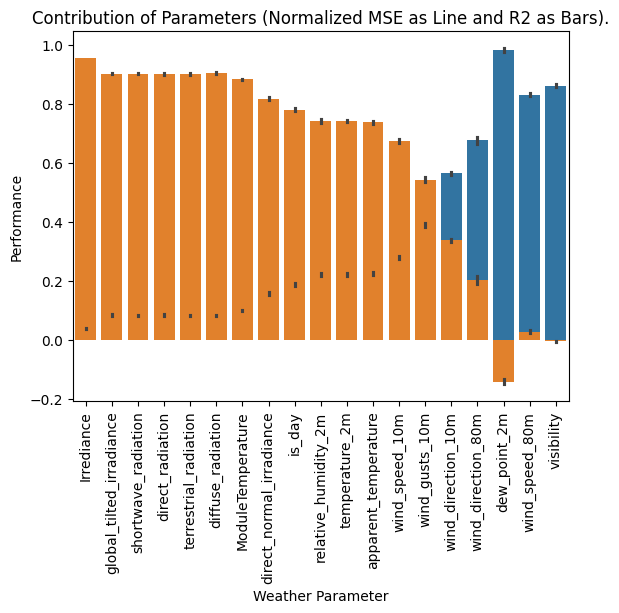

In [44]:
vdf_seq_result = df_seq_result.copy()
vdf_seq_result['MSE'] = (df_seq_result['MSE']/df_seq_result['MSE'].max())
vdf_seq_result['Rank'] = 1-(df_seq_result['Rank']/df_seq_result['Rank'].max())
plt.figure()
sns.barplot(vdf_seq_result, x='Feature', y='MSE')
# sns.barplot(vdf_seq_result, x='Feature', y='Rank')
sns.barplot(vdf_seq_result, x='Feature', y='R2')
plt.xlabel('Weather Parameter')
plt.ylabel('Performance')
a = plt.xticks(rotation=90)
a = plt.title('Contribution of Parameters (Normalized MSE as Line and R2 as Bars).')

<Axes: xlabel='Feature', ylabel='Rank'>

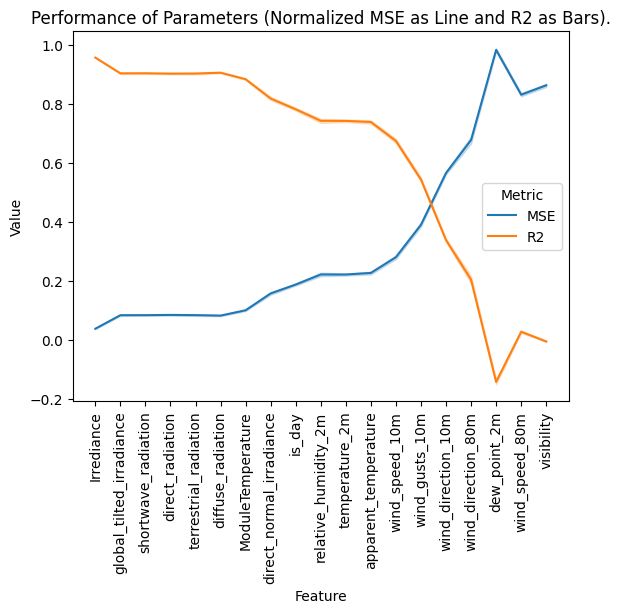

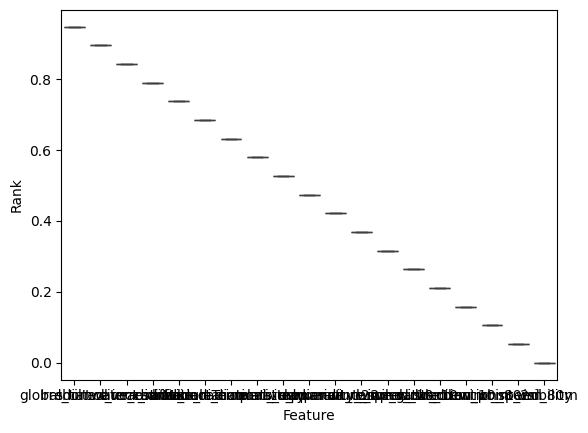

In [57]:
mdf_seq_result = vdf_seq_result.melt(id_vars=['Feature', 'Run', 'Rank'], var_name='Metric', value_name='Value')
plt.figure()
sns.lineplot(mdf_seq_result, x='Feature', y='Value', hue='Metric')
a = plt.xticks(rotation=90)
a = plt.title('Performance of Parameters (Normalized MSE as Line and R2 as Bars).')


plt.figure()
sns.boxplot(mdf_seq_result, x='Feature', y='Rank')

In [69]:
df_seq_result.groupby(['Feature'], as_index=False).mean()

,Feature,Rank,MSE,R2,Run
0,apparent_temperature,10.0,18807.784907,0.743803,4.5
1,dew_point_2m,15.0,77477.348649,-0.050290,4.5
2,diffuse_radiation,5.0,8498.559946,0.883951,4.5
3,direct_normal_irradiance,6.0,13291.901707,0.819296,4.5
4,direct_radiation,3.0,8249.678038,0.887609,4.5
5,global_tilted_irradiance,1.0,8526.050054,0.884015,4.5
6,is_day,7.0,15890.047080,0.784484,4.5
7,relative_humidity_2m,8.0,18671.293686,0.747483,4.5
8,shortwave_radiation,2.0,8629.216669,0.882101,4.5
9,temperature_2m,9.0,18805.295627,0.745585,4.5


#### Information Gain

In [35]:
def compute_entropy(probabilities):
    probabilities = np.clip(probabilities, 1e-12, None)
    return -np.sum(probabilities * np.log(probabilities))

In [ ]:
df_seq_result = {'Feature': [], 'MSE': [], 'R2': []}
for f in dfX.columns:
    # x = dfX.drop(columns=f)
    x = dfX.loc[:, [f]]
    X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2)
    mdl = tree.DecisionTreeRegressor(max_depth=len(X_cols))
    mdl = mdl.fit(X_train, y_train)
    y_pred = mdl.predict(X_test)
    df_seq_result['MSE'] += [mean_squared_error(y_test, y_pred)]
    df_seq_result['R2'] += [r2_score(y_test, y_pred)]
    df_seq_result['Feature'] += [f]
df_seq_result = pd.DataFrame(df_seq_result)
df_seq_result

In [ ]:
# df_mse=df_seq_result.loc[:,['MSE','Feature','Run']].pivot(columns=['Run'],index='Feature')
# df_mse = df_seq_result[df_seq_result['Run'] == 0].loc[:, ['Feature', 'R2']]

mse_data = df_seq_result['MSE'].values
overall_prob = mse_data / mse_data.sum()
entropies = - overall_prob * np.log(np.clip(overall_prob, 1e-12, None))
# overall_entropies = -np.sum(overall_prob * np.log(np.clip(overall_prob, 1e-12, None)))
# entropies = []
# for i in range(len(mse_data)):
#     prob = np.delete(mse_data, i) / overall_prob.sum()  # Normalize remaining MSEs
#     # prob = np.delete(mse_data, i) / np.delete(mse_data, i).sum()  # Normalize remaining MSEs
#     entropies.append(compute_entropy(prob))

info_gains = entropies.sum() - entropies
# info_gains = [overall_entropy - entropy for entropy in entropies]

print("Feature Eliminated\tEntropy\t\tInformation Gain")
for depth, feature in enumerate(dfX.columns):
    print(f"{feature}\t\t\t{entropies[depth]:.4f}\t\t{info_gains[depth]:.4f}")

In [ ]:
# sns.lineplot(y=info_gains/sum(info_gains), x=dfX.columns)
# sns.lineplot(y=entropies/sum(entropies), x=dfX.columns)
# sns.lineplot(y=info_gains, x=dfX.columns)
sns.barplot(y=entropies, x=dfX.columns)
a = plt.xticks(rotation=90)
plt.ylim(min(entropies)-0.0001*min(entropies), max(entropies)+0.0001*max(entropies))
a = plt.title('Entropy of Weather Parameters based on MSE')
a = plt.xlabel('Weather Parameter')
a = plt.ylabel('Entropy')

In [ ]:
sns.barplot(y=info_gains, x=dfX.columns)
a = plt.xticks(rotation=90)
plt.ylim(min(info_gains)-0.001*min(info_gains), max(info_gains)+0.001*max(info_gains))
a = plt.title('Information Gain of Weather Parameters based on MSE')
a = plt.xlabel('Weather Parameter')
a = plt.ylabel('Entropy')

In [ ]:
sns.lineplot(y=(info_gains/sum(info_gains)), x=dfX.columns, color='red')
sns.lineplot(y=entropies/sum(entropies), x=dfX.columns)
a = plt.xticks(rotation=90)
# plt.ylim(min(entropies)-0.0001*min(entropies), max(entropies)+0.0001*max(entropies))
a = plt.title('Entropy of Weather Parameters based on MSE')
a = plt.xlabel('Weather Parameter')
a = plt.ylabel('Entropy')